## Notebook outline
1. Imports and configuration
2. Data collection and exploration
3. Data cleaning
4. Train/test split
5. Exploratory data analysis
6. Preprocessing pipeline
7. Model definitions
8. Training
9. Evaluation
10. Effect of the price cap
11. Visual model comparison
12. Feature importance
13. Save the best model
14. Conclusions and limitations

## 1. Imports and Configuration

This section loads the libraries and fixes the settings in one place:
- `RANDOM_STATE = 42` makes the split and the models repeatable.
- `TEST_SIZE = 0.20` keeps 20% of the data aside for the final test.
- `PRICE_CAP = 500_001` is the value at which the dataset stops recording higher prices.

In [39]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from src.data_preprocessing import add_features   # <-- NEW LINE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "median_house_value"
PRICE_CAP = 500_001
DATA_PATH = Path("data/housing.csv")

## 2. Data Collection and Exploration

Before changing anything, I inspect the raw file: its size, column types, missing values, duplicates, the categories in the text column, and the range of the target.

In [40]:
df_raw = pd.read_csv(DATA_PATH)
print(df_raw.shape)
df_raw.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [41]:
df_raw.info()
print("Duplicates:", df_raw.duplicated().sum())
print("Rows at the price cap:", (df_raw[TARGET] >= PRICE_CAP).sum())
df_raw.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB
Duplicates: 0
Rows at the price cap: 965


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [42]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [43]:
df_raw["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

### Observations
- The file has **20,640 rows and 10 columns**: 8 numeric features, one categorical feature (`ocean_proximity`) and the numeric target.
- **Missing values:** only `total_bedrooms` has gaps, **207 rows** (about 1%).
- **Duplicates:** none.
- **`ocean_proximity`** has five categories. `<1H OCEAN` (9,136) and `INLAND` (6,551) dominate, while `ISLAND` has only 5 rows, so a model can learn little about it.
- **Price cap:** the maximum `median_house_value` is 500,001, and **965 districts** sit at that value. The data records "500,001 or more", so true prices above it are hidden. This is the main data limitation of the project.
- Features such as `total_rooms` and `population` have very large maximums compared with their medians, so a few districts are far larger than typical.

## 3. Data Cleaning

Cleaning rules:
1. Convert the target to a number and drop rows where it is missing or not positive.
2. Drop exact duplicate rows.
3. **Do not fill the missing `total_bedrooms` values here.** Imputation happens inside the pipeline, so the fill value is learned from training data only and nothing leaks from the test set.
4. Add three ratio features with `add_features`: `rooms_per_household`, `bedrooms_per_room` and `population_per_household`. They use only each row's own values, so adding them before the split does not leak information from the test set.

In [44]:
df = df_raw.copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].notna() & (df[TARGET] > 0)].drop_duplicates().reset_index(drop=True)

df = add_features(df)   # <-- NEW LINE

cleaning_summary = pd.Series({
    "rows_before": len(df_raw),
    "rows_after": len(df),
    "rows_removed": len(df_raw) - len(df),
    "missing_total_bedrooms": int(df["total_bedrooms"].isna().sum()),
})
cleaning_summary

rows_before               20640
rows_after                20640
rows_removed                  0
missing_total_bedrooms      207
dtype: int64

### Cleaning result
No rows were removed, because there were no duplicates or invalid targets. All 20,640 rows are kept, and the 207 missing `total_bedrooms` values are handled later by the pipeline.

## 4. Train/Test Split

The data is split **before any preprocessing or modelling** into 80% for training and 20% for testing, using `random_state=42`. The test set is used once, at the end, to measure how the models do on districts they have never seen.

In [45]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print("Missing total_bedrooms in train:", X_train["total_bedrooms"].isna().sum())
print("Missing total_bedrooms in test: ", X_test["total_bedrooms"].isna().sum())

Train: 16,512 rows | Test: 4,128 rows
Missing total_bedrooms in train: 0
Missing total_bedrooms in test:  207


### Split result
The training set has **16,512 rows** and the test set has **4,128 rows**.

**Note:** with this seed, all 207 missing `total_bedrooms` values fall in the test set, so the training data has none. The imputer is still needed in the pipeline: it fills the test rows (and any future input) with the median learned from the training data. With a different seed the missing values would be spread across both sets.

## 5. Exploratory Data Analysis

I explore **only the training data**, so decisions about the models are not influenced by the test set. The charts look at the target's distribution, the effect of income, the effect of ocean proximity and location, and the correlations between variables.

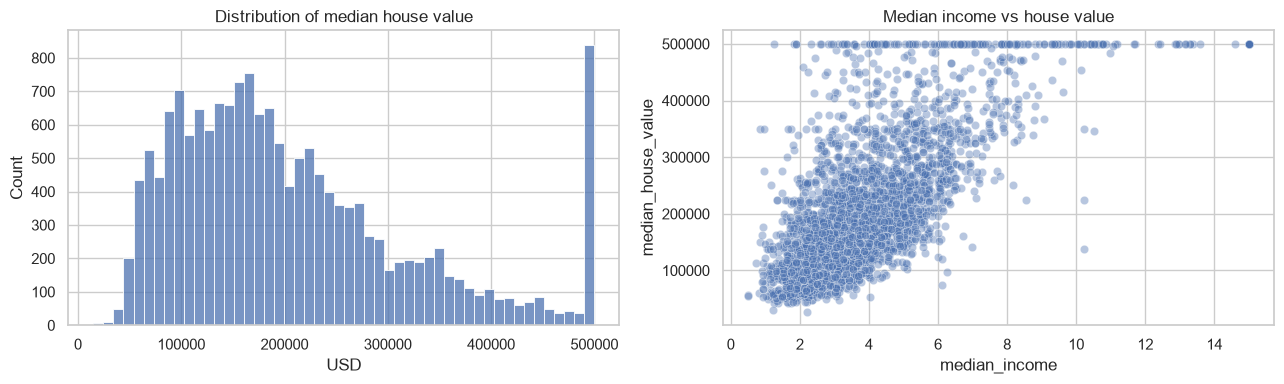

In [46]:
train_df = X_train.assign(**{TARGET: y_train})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train_df[TARGET], bins=50, ax=axes[0])
axes[0].set(title="Distribution of median house value", xlabel="USD")
sns.scatterplot(data=train_df.sample(3000, random_state=RANDOM_STATE),
                x="median_income", y=TARGET, alpha=0.4, ax=axes[1])
axes[1].set(title="Median income vs house value")
plt.tight_layout()
plt.show()

**Target and income.** Prices are right-skewed (skewness about 1). The spike at the right edge is the 500,001 cap, which affects about 4.8% of training districts. `median_income` has the strongest relationship with price: richer districts have more expensive houses.

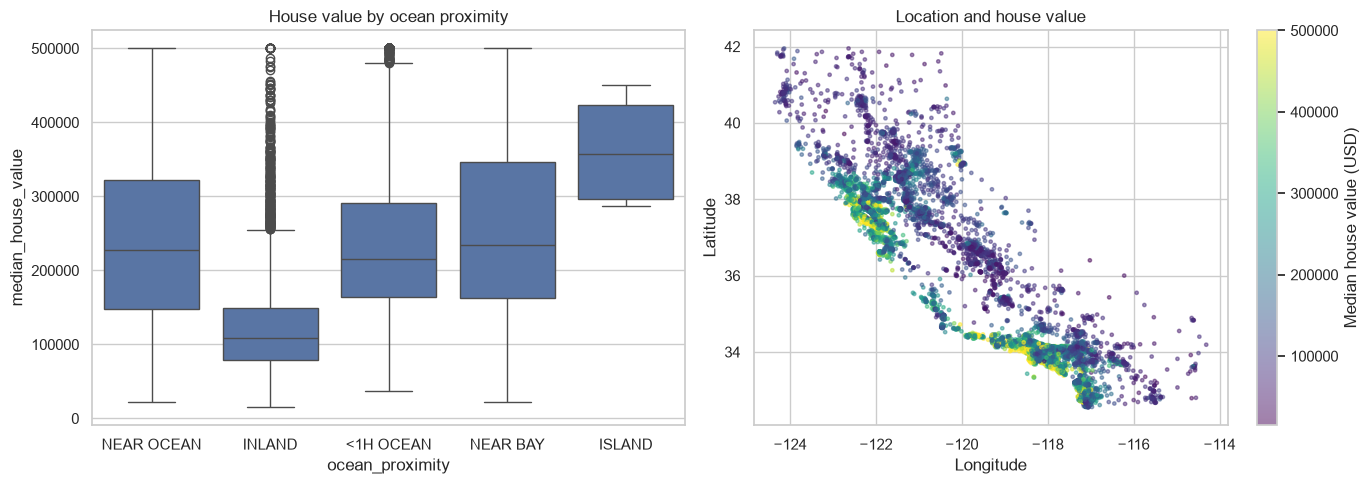

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train_df, x="ocean_proximity", y=TARGET, ax=axes[0])
axes[0].set(title="House value by ocean proximity")

sc = axes[1].scatter(train_df["longitude"], train_df["latitude"],
                     c=train_df[TARGET], cmap="viridis", s=6, alpha=0.5)
plt.colorbar(sc, ax=axes[1], label="Median house value (USD)")
axes[1].set(title="Location and house value", xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
plt.show()

**Ocean proximity and location.** Inland districts are the cheapest (median about $109,000). Districts near the bay (about $235,000), near the ocean (about $228,000) and within one hour of the ocean (about $215,000) are much higher. `ISLAND` has only 5 rows, so its median should not be trusted. The map shows high prices along the coast and around the big metropolitan areas, a pattern a straight line cannot capture, so tree-based models may do better.

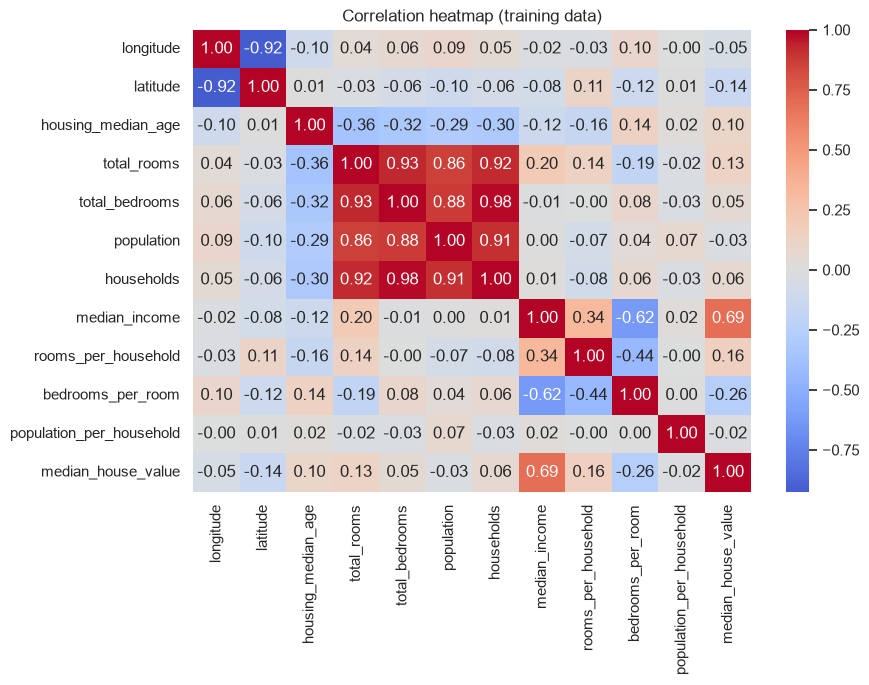

In [48]:
plt.figure(figsize=(9, 6))
sns.heatmap(train_df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (training data)")
plt.show()

**Correlations.** `median_income` has a correlation of about 0.69 with the price, and every other feature is below 0.26 in absolute value (the next strongest is the new `bedrooms_per_room` ratio at about -0.26). Rooms, bedrooms, population and households are strongly related to each other, which can make Linear Regression coefficients unstable. Correlation is not causation: these patterns describe the data and do not prove what causes prices.

## 6. Preprocessing Pipeline

Every model uses the same preprocessing, built with a `ColumnTransformer` inside a `Pipeline`:

| Column type | Steps |
|---|---|
| Numeric (11 columns: 8 original + 3 ratio features) | median imputation, then standard scaling |
| Categorical (`ocean_proximity`) | most-frequent imputation, then one-hot encoding (unknown categories ignored) |

**Why a pipeline?**
- The imputer, scaler and encoder are **fitted on training data only**, which prevents data leakage.
- The exact same steps are applied automatically when predicting for new data, which matters for the Streamlit app.
- Scaling helps Linear Regression and makes its coefficients comparable. It does not harm the tree models.

In [49]:
NUM_COLS = X_train.select_dtypes(include="number").columns.tolist()
CAT_COLS = ["ocean_proximity"]


def build_preprocessor():
    """Return a fresh, unfitted preprocessing step for any model."""
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, NUM_COLS),
        ("cat", categorical, CAT_COLS),
    ])


print("Numeric columns:", NUM_COLS)
print("Categorical columns:", CAT_COLS)

Numeric columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical columns: ['ocean_proximity']


## 7. Model Definitions

Three regression models are compared. Each one is wrapped in the **same** `Pipeline`: the shared preprocessing step followed by the model.

| Model | Role | Settings |
|---|---|---|
| Linear Regression | Baseline: a straight-line relationship | defaults |
| Decision Tree | Learns if/then splits, can capture non-linear patterns | `max_depth=8`, `min_samples_leaf=10` |
| Random Forest | Averages many trees, usually more accurate and stable | `n_estimators=200`, `min_samples_leaf=2` |

**Why limit the tree?** An unrestricted Decision Tree memorises the training data (overfitting). Limiting its depth and leaf size keeps it general. The Random Forest averages many trees, which reduces overfitting by itself.

In [50]:
def build_models():
    """Return a fresh dictionary of unfitted full pipelines (preprocessing + model)."""
    estimators = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(
            max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
        ),
    }
    return {
        name: Pipeline([("prep", build_preprocessor()), ("model", est)])
        for name, est in estimators.items()
    }


pipelines = build_models()
list(pipelines)

['Linear Regression', 'Decision Tree', 'Random Forest']

## 8. Training

Each pipeline is fitted on the **training set only**. During `fit`, the imputer, scaler and encoder learn their values from the training rows, then the model learns from the transformed data.

In [51]:
import time

fit_times = {}
for name, pipe in pipelines.items():
    start = time.time()
    pipe.fit(X_train, y_train)
    fit_times[name] = time.time() - start
    print(f"{name:<18} trained in {fit_times[name]:.2f}s")

Linear Regression  trained in 0.07s
Decision Tree      trained in 0.16s
Random Forest      trained in 2.33s


## 9. Evaluation

Metrics used (all on the original dollar scale, except R²):
- **MAE**: the average size of the error, in dollars. Easy to explain.
- **RMSE**: like MAE but punishes large errors more.
- **R²**: the share of price variation the model explains (1.0 is perfect, 0 is no better than predicting the average).

I report **train R²**, **5-fold cross-validated R²** (on training data only) and **test R²**. If train R² is much higher than the other two, the model is overfitting. The test set is used here once, for the final comparison.

In [52]:
def evaluate(name, pipe):
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)

    # Fresh unfitted copy so cross-validation does not touch the fitted pipeline
    cv_scores = cross_val_score(
        build_models()[name], X_train, y_train, cv=5, scoring="r2", n_jobs=-1
    )
    return {
        "Model": name,
        "Train R²": r2_score(y_train, pred_train),
        "CV R² (mean)": cv_scores.mean(),
        "CV R² (std)": cv_scores.std(),
        "Test R²": r2_score(y_test, pred_test),
        "Test MAE ($)": mean_absolute_error(y_test, pred_test),
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_test)),
    }


results = pd.DataFrame([evaluate(n, p) for n, p in pipelines.items()]).set_index("Model")
results.round(3)

,Train R²,CV R² (mean),CV R² (std),Test R²,Test MAE ($),Test RMSE ($)
Model,,,,,,
Linear Regression,0.658,0.655,0.012,0.635,49645.492,69127.038
Decision Tree,0.775,0.725,0.007,0.709,41606.739,61719.631
Random Forest,0.961,0.812,0.007,0.813,31758.460,49447.385


### Results
| Model | Train R² | CV R² | Test R² | Test MAE | Test RMSE |
|---|---|---|---|---|---|
| Linear Regression | 0.658 | 0.655 | 0.635 | $49,645 | $69,127 |
| Decision Tree | 0.775 | 0.725 | 0.709 | $41,607 | $61,720 |
| Random Forest | 0.961 | 0.812 | 0.813 | $31,758 | $49,447 |

- **Random Forest is the best model** on every metric. It explains about 81% of the price variation and its typical error is about $32,000, compared with about $50,000 for Linear Regression.
- Cross-validated R² and test R² are very close for all three models, so the test result is not a lucky split.
- **Linear Regression** has similar train and test scores, so it is not overfitting. It is simply too simple for this data (it underfits).
- **Random Forest** has a train R² (0.96) well above its test R² (0.81). Some memorisation of the training data is normal for forests, and the test score is still the best of the three, so this is acceptable. The gap is worth mentioning as a limitation.

## 10. Effect of the Price Cap

The target is capped at 500,001, so for those districts the true price is unknown and the model can never predict above the cap in a meaningful way. To see how much this affects the scores, I repeat the evaluation on **test districts below the cap only**.

In [53]:
uncapped = y_test < PRICE_CAP
print(f"Test rows at the cap: {(~uncapped).sum()} of {len(y_test)}\n")

cap_rows = []
for name, pipe in pipelines.items():
    pred = pipe.predict(X_test[uncapped])
    cap_rows.append({
        "Model": name,
        "MAE below cap ($)": mean_absolute_error(y_test[uncapped], pred),
        "R² below cap": r2_score(y_test[uncapped], pred),
    })
pd.DataFrame(cap_rows).set_index("Model").round(3)

Test rows at the cap: 179 of 4128



,MAE below cap ($),R² below cap
Model,,
Linear Regression,45593.593,0.609
Decision Tree,39326.909,0.674
Random Forest,29761.176,0.795


### Cap check
179 of the 4,128 test districts are at the cap. Excluding them, the MAE is a little lower for every model (Random Forest: about $29,800) and R² is slightly lower (about 0.80 for Random Forest). The **ranking of the models does not change**, so the conclusion does not depend on the cap. Predictions for very expensive areas should still be treated with caution.

## 11. Visual Model Comparison

Two charts: actual versus predicted prices for every model (points close to the dashed line are good predictions), and the residuals of the best model (actual minus predicted).

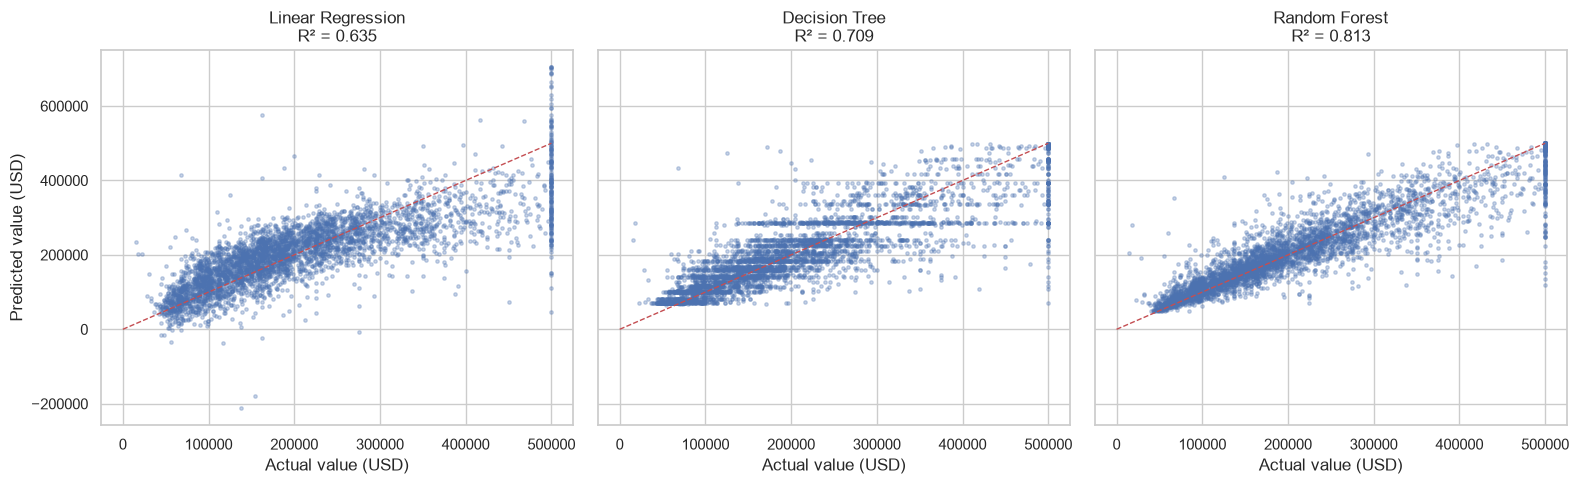

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [0, y_test.max()]
for ax, (name, pipe) in zip(axes, pipelines.items()):
    pred = pipe.predict(X_test)
    ax.scatter(y_test, pred, s=6, alpha=0.3)
    ax.plot(lims, lims, "r--", lw=1)
    ax.set(title=f"{name}\nR² = {r2_score(y_test, pred):.3f}",
           xlabel="Actual value (USD)")
axes[0].set_ylabel("Predicted value (USD)")
plt.tight_layout()
plt.show()

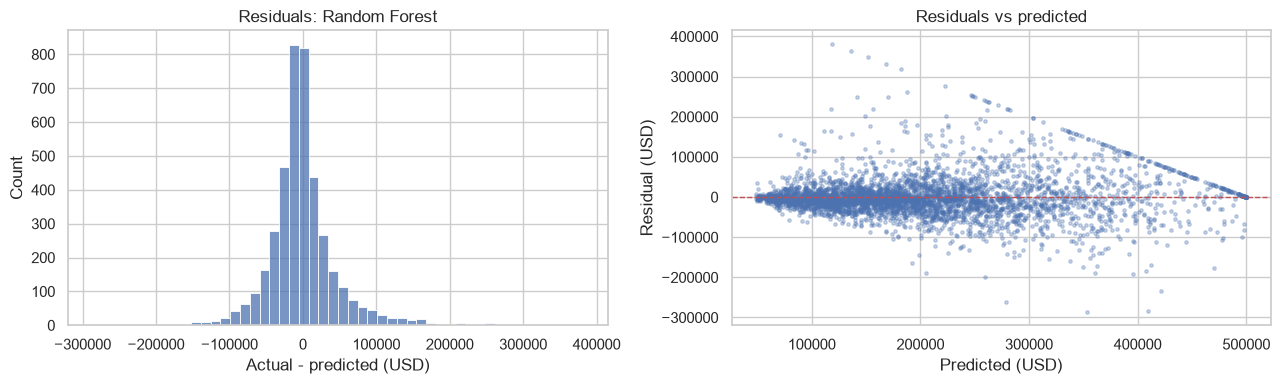

Best model: Random Forest


In [55]:
best_name = results["Test R²"].idxmax()
best_pipe = pipelines[best_name]
residuals = y_test - best_pipe.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(residuals, bins=50, ax=axes[0])
axes[0].set(title=f"Residuals: {best_name}", xlabel="Actual - predicted (USD)")
axes[1].scatter(best_pipe.predict(X_test), residuals, s=6, alpha=0.3)
axes[1].axhline(0, color="r", ls="--", lw=1)
axes[1].set(title="Residuals vs predicted", xlabel="Predicted (USD)", ylabel="Residual (USD)")
plt.tight_layout()
plt.show()
print("Best model:", best_name)

**Reading the charts.** Linear Regression's points form a wide band and it predicts negative prices for a few cheap districts (10 in the test set), which is impossible for a house value. The Decision Tree shows horizontal stripes because it predicts one value per leaf. The Random Forest stays closest to the dashed line. Its errors are centred near zero, but they grow with price: about $17,000 on average for the cheapest quarter of predictions against about $50,000 for the most expensive quarter. Districts at the price cap are underpredicted by about $76,000 on average, which matches the cap limitation noted earlier.

## 12. Feature Importance (Random Forest)

The Random Forest reports how much each feature contributed to its splits. This shows **what the model relies on**, not what causes prices. Note that `ocean_proximity` has been one-hot encoded, so each category appears as its own column.

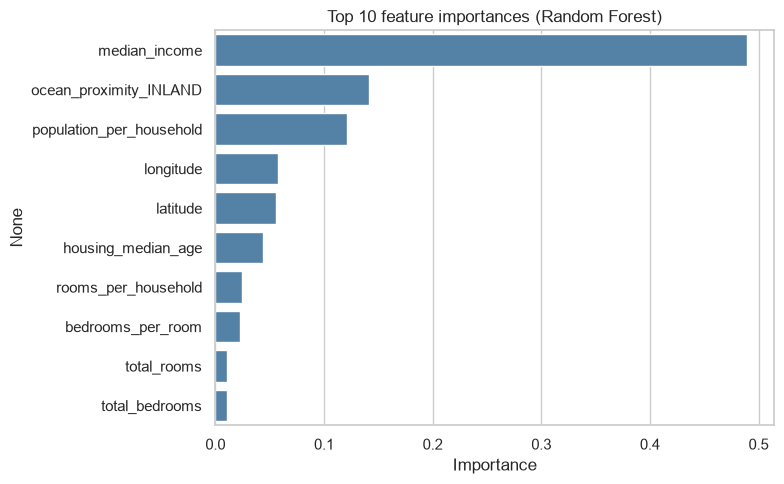

median_income               0.490
ocean_proximity_INLAND      0.142
population_per_household    0.121
longitude                   0.057
latitude                    0.056
housing_median_age          0.044
rooms_per_household         0.024
bedrooms_per_room           0.022
dtype: float64

In [56]:
rf_pipe = pipelines["Random Forest"]
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()
importances = (
    pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=feature_names)
    .rename(lambda n: n.split("__", 1)[1])
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index, color="steelblue")
plt.title("Top 10 feature importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
importances.head(8).round(3)

### Feature importance result
`median_income` is by far the most important feature (about 49% of the total), followed by being `INLAND` (about 14%) and the engineered feature `population_per_household` (about 12%). The location pair `longitude` and `latitude` contributes about 6% each. Together, income, location and how crowded a district is explain most of what the model uses. The ratio feature ranking third shows that the feature engineering added useful information, even though the overall score did not improve. Importances can be split between correlated features (such as rooms, bedrooms and households), so small differences between them should not be over-interpreted.

## 13. Save the Best Model

The full pipeline (preprocessing + Random Forest) is saved as one file, so the Streamlit app can load it and predict from raw inputs without repeating any preprocessing code. I also save the metadata the app needs: column names, categories and the price cap.

In [62]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(best_pipe, MODEL_DIR / "best_model.joblib", compress=3)

metadata = {
    "best_model": best_name,
    "feature_columns": X_train.columns.tolist(),
    "numeric_columns": NUM_COLS,
    "categorical_columns": CAT_COLS,
    "ocean_categori es": sorted(X_train["ocean_proximity"].unique().tolist()),
    "price_cap": PRICE_CAP,
    "test_r2": float(results.loc[best_name, "Test R²"]),
    "test_mae": float(results.loc[best_name, "Test MAE ($)"]),
    "numeric_ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in NUM_COLS},
}
joblib.dump(metadata, MODEL_DIR / "metadata.joblib")
results.round(4).to_csv(MODEL_DIR / "model_comparison.csv")

print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

Saved: ['best_model.joblib', 'metadata.joblib', 'model_comparison.csv']


In [63]:
# Sanity check: reload the saved model and predict one raw row
loaded = joblib.load(MODEL_DIR / "best_model.joblib")
sample = X_test.iloc[[0]]
print("Input:\n", sample.T, "\n")
print(f"Predicted: ${loaded.predict(sample)[0]:,.0f}")
print(f"Actual:    ${y_test.iloc[0]:,.0f}")
assert np.allclose(loaded.predict(X_test), best_pipe.predict(X_test)), "Reloaded model differs!"
print("Reloaded model matches the original.")

Input:
                              20046
longitude                  -119.01
latitude                     36.06
housing_median_age            25.0
total_rooms                 1505.0
total_bedrooms                 NaN
population                  1392.0
households                   359.0
median_income               1.6812
ocean_proximity             INLAND
rooms_per_household       4.192201
bedrooms_per_room              NaN
population_per_household  3.877437 

Predicted: $52,650
Actual:    $47,700
Reloaded model matches the original.


## 14. Conclusions and Limitations

**Conclusions**
- Random Forest is the best of the three models (test R² about 0.81, MAE about $32,000). The Decision Tree is second and Linear Regression, the baseline, is last.
- Income and location drive the predictions, and the people-per-household ratio is the third most important feature.
- The ratio features gave a small gain to the Linear Regression and Decision Tree models and made no real difference to the Random Forest.
- Using one shared pipeline kept the comparison fair and avoided data leakage.

**Limitations**
- **Old data:** the 1990 census. Prices and neighbourhoods have changed a lot, so this must not be used to value real property today.
- **Price cap:** about 4.7% of districts are recorded as 500,001, so the highest prices are unknown.
- **District-level data:** predictions are for a district's median value, not for an individual house.
- **Rare category:** `ISLAND` has only 5 rows, so predictions for it are unreliable.
- **Overfitting gap:** the Random Forest fits the training data much better than the test data. No hyperparameter tuning was done.

**Possible next steps:** tune hyperparameters with `GridSearchCV`, try Gradient Boosting, and add geographic features such as distance to major cities.

> **Disclaimer:** educational project only. Not a property valuation, appraisal or financial advice.